In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", None, "display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
from src import config as C

# 05 — İstatistiksel Analiz

EDA bize örüntüleri **gösterdi**. İstatistik bize şunu söyler: *"Bu fark şans eseri olabilir mi?"*

| Soru | Araç |
|---|---|
| Churn oranı ne kadar kesin ölçülmüş? | **Güven aralığı** (Wilson) |
| Kategorik değişken ↔ churn ilişkisi var mı? | **Ki-kare testi** + etki büyüklüğü **Cramér's V** |
| Sayısal değişkenin dağılımı iki grupta farklı mı? | **Mann-Whitney U** + etki büyüklüğü |
| Çok test yaptık; "tesadüfen anlamlı" çıkanları nasıl ayıklarız? | **Çoklu test düzeltmesi** (Benjamini-Hochberg FDR) |
| Diğer değişkenler sabitken etki nedir? | **Lojistik regresyon (statsmodels)** → odds ratio |

In [2]:
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

df = pd.read_csv(C.CLEAN_PATH)
from src.features import add_features
df = add_features(df)

## 5.1 Churn oranı için %95 güven aralığı
Elimizdeki 1800 müşteri bir **örneklem**. Gerçek (popülasyon) churn oranı tam olarak %8,22 olmayabilir. **Wilson aralığı** oranlar için kullanılan, küçük oranlarda normal yaklaşıma göre daha güvenilir bir yöntemdir.

In [3]:
k, n = int(df.churn.sum()), len(df)
lo, hi = proportion_confint(k, n, alpha=0.05, method="wilson")
display(Markdown(f"Churn oranı **{k/n:.2%}** ({k}/{n}); %95 güven aralığı: **[{lo:.2%}, {hi:.2%}]**"))

Churn oranı **8.22%** (148/1800); %95 güven aralığı: **[7.04%, 9.58%]**

## 5.2 Kategorik değişkenler: Ki-kare + Cramér's V

* **H0:** Değişken ile churn bağımsızdır. **H1:** İlişki vardır.
* p < 0,05 ise H0 reddedilir — ama **p-değeri ilişkinin gücünü söylemez** (büyük örneklemde küçük fark da "anlamlı" çıkar). Bu yüzden **Cramér's V** (0 = ilişki yok, 1 = mükemmel) ile gücü de raporlarız.
* Ki-kare varsayımı: beklenen hücre sayıları ≥ 5. Aşağıda en küçük beklenen değeri de gösteriyoruz.

In [4]:
def cramers_v(table):
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum(); k = min(table.shape) - 1
    return np.sqrt(chi2 / (n * k))

rows = []
for col in ["contract_type", "plan", "region", "payment_method", "device_type", "tenure_group"]:
    sub = df.dropna(subset=[col])                      # eksik kategori testten çıkarılır (adet raporlanır)
    table = pd.crosstab(sub[col], sub["churn"])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    rows.append({"değişken": col, "n_kullanılan": len(sub), "chi2": chi2, "dof": dof, "p_değeri": p,
                 "cramers_V": cramers_v(table), "min_beklenen_hücre": expected.min()})
cat_tests = pd.DataFrame(rows)
cat_tests["p_BH_düzeltmeli"] = multipletests(cat_tests["p_değeri"], method="fdr_bh")[1]
display(cat_tests.sort_values("p_değeri"))

,değişken,n_kullanılan,chi2,dof,p_değeri,cramers_V,min_beklenen_hücre,p_BH_düzeltmeli
0,contract_type,1800,39.381,2,0.000,0.148,21.707,0.000
5,tenure_group,1800,32.711,4,0.000,0.135,10.689,0.000
1,plan,1800,6.557,2,0.038,0.060,31.491,0.075
2,region,1768,8.780,5,0.118,0.070,23.051,0.177
4,device_type,1800,2.157,2,0.340,0.035,13.156,0.408
3,payment_method,1773,1.213,3,0.750,0.026,9.323,0.750


**Okuma:** `contract_type` ve `tenure_group` çok güçlü kanıt (düzeltmeden sonra da). `plan` ham p-değerinde sınırda anlamlı (≈0,04) ama **çoklu test düzeltmesinden sonra anlamlılığını kaybediyor** (≈0,08). `region`, `device_type`, `payment_method` anlamlı değil. **Cramér's V değerleri küçük** (en büyüğü ≈ 0,15): ilişkiler gerçek ama zayıf-orta büyüklükte. *EDA'da Marmara düşük görünmüştü; ama bu fark çoklu test düzeltmesinden sonra şansla açıklanabilir bir düzeyde.*

> **Çoklu test sorunu:** 6 test yaparsan, hepsi gerçekte ilişkisiz olsa bile ~%26 ihtimalle en az biri p<0,05 çıkar. Benjamini-Hochberg düzeltmesi bunu kontrol eder.

## 5.3 Sayısal değişkenler: Mann-Whitney U
Neden t-testi değil? Sayaç değişkenleri (0,1,2…) ve puanlar normal dağılmıyor; Mann-Whitney **dağılım varsayımı yapmaz** (sıra tabanlıdır).
**Etki büyüklüğü:** "rank-biserial" korelasyon `r = 2U/(n₁n₂) − 1` — ayrılan grubun değerlerinin ayrılmayandan büyük olma eğilimini ölçer (−1…+1).

In [5]:
rows = []
for col in ["tenure_months", "satisfaction_score", "complaints_6m", "support_calls_6m", "late_payments_6m", "monthly_usage_hours", "age", "discount_rate"]:
    g0 = df.loc[df.churn == 0, col].dropna(); g1 = df.loc[df.churn == 1, col].dropna()
    U, p = stats.mannwhitneyu(g1, g0, alternative="two-sided")
    rows.append({"değişken": col, "medyan_ayrılan": g1.median(), "medyan_kalan": g0.median(),
                 "U": U, "p_değeri": p, "rank_biserial_r": 2 * U / (len(g1) * len(g0)) - 1})
num_tests = pd.DataFrame(rows)
num_tests["p_BH_düzeltmeli"] = multipletests(num_tests["p_değeri"], method="fdr_bh")[1]
display(num_tests.sort_values("p_değeri"))

,değişken,medyan_ayrılan,medyan_kalan,U,p_değeri,rank_biserial_r,p_BH_düzeltmeli
0,tenure_months,24.500,39.000,"89,556.500",0.000,-0.267,0.000
1,satisfaction_score,5.400,6.250,"81,579.000",0.000,-0.271,0.000
2,complaints_6m,0.000,0.000,"140,738.000",0.000,0.151,0.001
3,support_calls_6m,2.000,1.000,"142,803.000",0.000,0.168,0.001
4,late_payments_6m,0.000,0.000,"128,341.000",0.253,0.050,0.404
6,age,45.000,47.000,"109,959.500",0.466,-0.037,0.621
7,discount_rate,0.100,0.050,"120,502.000",0.765,-0.014,0.875
5,monthly_usage_hours,42.250,42.100,"111,208.000",0.958,-0.003,0.958


**Okuma:** `tenure_months`, `satisfaction_score`, `complaints_6m`, `support_calls_6m` anlamlı farklı; `monthly_usage_hours`, `age`, `late_payments_6m`, `discount_rate` anlamlı değil. Etki büyüklükleri (|r| ≈ 0,15–0,27) **küçük-orta**. Dikkat: `late_payments_6m` (ödeme gecikmesi) sezgisel olarak önemli görünse de bu veride anlamlı bir fark yok.

## 5.4 Eksiklik bilgi taşıyor mu? (Fisher exact testi)
`region` eksik olan 32 müşteride churn çok yüksek görünüyordu. Küçük örneklemde ki-kare yerine **Fisher exact** kullanılır.

In [6]:
rows = []
for col in ["age", "region", "monthly_usage_hours", "payment_method", "satisfaction_score"]:
    m = df[col].isna()
    table = [[(m & (df.churn == 1)).sum(), (m & (df.churn == 0)).sum()], [(~m & (df.churn == 1)).sum(), (~m & (df.churn == 0)).sum()]]
    odds, p = stats.fisher_exact(table)
    rows.append({"sütun": col, "eksik_adet": int(m.sum()), "churn_eksik": df.loc[m, "churn"].mean(), "churn_dolu": df.loc[~m, "churn"].mean(), "p_değeri": p})
miss_tests = pd.DataFrame(rows); miss_tests["p_BH_düzeltmeli"] = multipletests(miss_tests["p_değeri"], method="fdr_bh")[1]
display(miss_tests)

,sütun,eksik_adet,churn_eksik,churn_dolu,p_değeri,p_BH_düzeltmeli
0,age,50,0.120,0.081,0.296,0.494
1,region,32,0.188,0.080,0.042,0.211
2,monthly_usage_hours,67,0.119,0.081,0.255,0.494
3,payment_method,27,0.111,0.082,0.482,0.603
4,satisfaction_score,82,0.073,0.083,1.000,1.000


**Okuma:** Düzeltmeden sonra eksiklik anlamlı bilgi taşıdığına dair **güçlü kanıt yok** (`region` en yakın aday ama n küçük). Bu yüzden basit imputasyon (medyan/mod) kullanıyoruz; ayrı "eksiklik göstergesi" sütunu eklemiyoruz. *Kanıt yokluğu, yokluğun kanıtı değildir:* örnek büyüdükçe bu karar yeniden gözden geçirilmeli.

## 5.5 Çoklu doğrusallık: `monthly_fee_tl` yeni bilgi taşıyor mu?
`ücret = plan fiyatı × (1 − indirim)` olduğunu biliyoruz. Ücreti plan ve indirimden regresyonla tahmin edersek R² kaç çıkar?

In [7]:
expected = df["plan"].map(C.PLAN_BASE_PRICE) * (1 - df["discount_rate"])
r2 = np.corrcoef(expected, df["monthly_fee_tl"])[0, 1] ** 2
display(Markdown(f"`plan fiyatı × (1 − indirim)` ile gerçek ücret arasındaki R² = **{r2:.6f}**, en büyük mutlak fark = **{(expected - df.monthly_fee_tl).abs().max():.4f} TL**"))

`plan fiyatı × (1 − indirim)` ile gerçek ücret arasındaki R² = **1.000000**, en büyük mutlak fark = **0.0000 TL**

**Sonuç:** Ücret, plan ve indirimden **tam olarak türüyor** (R² = 1). Modele eklemek yeni bilgi vermez, sadece çoklu doğrusallık yaratır. Bu yüzden `monthly_fee_tl` model girdilerinde yok; ama **iş analizinde** (gelir, riskteki gelir) kullanılıyor.

## 5.6 Çok değişkenli bakış: Lojistik regresyon (statsmodels) ve Odds Ratio
Tek tek testler, değişkenler birbirine bağlıyken yanıltabilir (ör. kısa süreli müşteriler aynı zamanda daha çok aylık sözleşmeli olabilir). **Diğerleri sabitken** her değişkenin etkisini görmek için lojistik regresyon kullanıyoruz.

* **Odds ratio (OR) = exp(katsayı).** OR > 1: risk artar; < 1: azalır. Sayısal değişkenleri standartlaştırdık → OR, "1 standart sapma artışın" etkisidir.
* Tam gözlemli satırlar kullanılır (eksik satisfaction nedeniyle ~82 satır dışarıda). Bu **çıkarım** analizidir; tahmin modelini Notebook 07'de ayrıca kuruyoruz.

In [8]:
cols = ["tenure_months", "satisfaction_score", "complaints_6m", "support_calls_6m", "late_payments_6m"]
d = df.dropna(subset=cols + ["contract_type", "plan"]).copy()
Z = (d[cols] - d[cols].mean()) / d[cols].std()
X = pd.concat([Z, pd.get_dummies(d[["contract_type", "plan"]], drop_first=True).astype(float)], axis=1)
X = sm.add_constant(X)
logit = sm.Logit(d["churn"], X).fit(disp=False)
ci = logit.conf_int()
res = pd.DataFrame({"OR": np.exp(logit.params), "OR_low": np.exp(ci[0]), "OR_high": np.exp(ci[1]), "p": logit.pvalues}).drop(index="const")
display(res.round(3))
display(Markdown(f"Kullanılan satır: **{len(d)}**, pseudo R² = **{logit.prsquared:.3f}** (düşük: churn çoğunlukla bu değişkenlerle açıklanamıyor)."))

,OR,OR_low,OR_high,p
tenure_months,0.598,0.495,0.721,0.000
satisfaction_score,0.681,0.559,0.831,0.000
complaints_6m,1.226,1.043,1.442,0.014
support_calls_6m,1.173,0.980,1.404,0.082
late_payments_6m,1.047,0.876,1.252,0.611
contract_type_Monthly,2.895,1.817,4.613,0.000
contract_type_Two-Year,0.553,0.232,1.318,0.181
plan_Premium,0.887,0.562,1.401,0.606
plan_Standard,0.604,0.397,0.918,0.018


Kullanılan satır: **1718**, pseudo R² = **0.118** (düşük: churn çoğunlukla bu değişkenlerle açıklanamıyor).

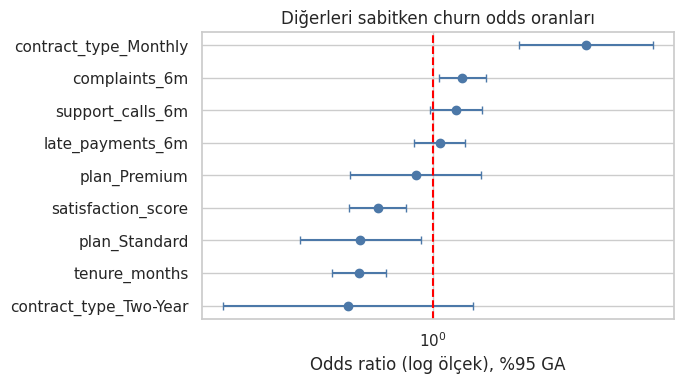

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
r = res.sort_values("OR")
ax.errorbar(r["OR"], r.index, xerr=[r["OR"] - r["OR_low"], r["OR_high"] - r["OR"]], fmt="o", color="#4c78a8", capsize=3)
ax.axvline(1, color="red", ls="--"); ax.set_xscale("log"); ax.set_xlabel("Odds ratio (log ölçek), %95 GA"); ax.set_title("Diğerleri sabitken churn odds oranları")
plt.tight_layout(); plt.show()

**Okuma (diğer değişkenler sabitken):**
* **Referans kategoriler:** sözleşme için `Annual`, plan için `Basic` (`drop_first=True` alfabetik ilk kategoriyi düşürür).
* **Aylık sözleşme**, yıllığa göre odds'u yaklaşık **2,9 kat** artırıyor (en güçlü kategorik etki). İki yıllık, yıllıktan ayırt edilebilir değil (aralık 1'i kapsıyor; yalnızca ~264 müşteri).
* **Memnuniyet** ve **abonelik süresi** arttıkça risk **azalıyor** (OR < 1); **şikâyet** arttıkça artıyor.
* `support_calls_6m` sınırda (aralık 1'e çok yakın), `late_payments_6m` etkisi diğerleri sabit tutulunca **yok** — tek başına anlamlı görünmeleri, şikâyet/memnuniyetle ilişkili olmalarından kaynaklanıyor olabilir.
* `plan_Standard` Basic'e göre daha düşük risk gösteriyor ama bu, çoklu karşılaştırma bağlamında zayıf kanıttır.
* Bu sonuçlar **nedensel değildir**; yalnızca gözlemsel ilişkilerdir.

## 5.7 Özellik tarama — yalnızca EĞİTİM verisinde (sızıntıyı önlemek için)
Modelde hangi değişkenleri kullanacağımıza karar verirken test kümesine bakmak, test sonucunu iyimserleştirir. Bu yüzden *aynı taramayı yalnızca eğitim verisinde* tekrarlıyoruz ve genel sonuçla tutarlı mı diye bakıyoruz.

In [10]:
from src.modeling import load_clean, split_data
tr, te = split_data(load_clean())
tr = add_features(tr)
screen = []
for col in ["tenure_months", "satisfaction_score", "complaints_6m", "support_calls_6m", "late_payments_6m", "monthly_usage_hours", "age", "discount_rate"]:
    g0, g1 = tr.loc[tr.churn == 0, col].dropna(), tr.loc[tr.churn == 1, col].dropna()
    U, p = stats.mannwhitneyu(g1, g0); screen.append({"değişken": col, "tür": "sayısal", "etki": abs(2 * U / (len(g1) * len(g0)) - 1), "p": p})
for col in ["contract_type", "plan", "region", "payment_method", "device_type"]:
    t = pd.crosstab(tr[col], tr["churn"]); chi2, p, *_ = stats.chi2_contingency(t); screen.append({"değişken": col, "tür": "kategorik", "etki": cramers_v(t), "p": p})
screen = pd.DataFrame(screen); screen["p_BH"] = multipletests(screen["p"], method="fdr_bh")[1]
display(screen.sort_values("p").round(4))

,değişken,tür,etki,p,p_BH
1,satisfaction_score,sayısal,0.323,0.000,0.000
8,contract_type,kategorik,0.144,0.000,0.000
0,tenure_months,sayısal,0.265,0.000,0.000
2,complaints_6m,sayısal,0.161,0.001,0.002
3,support_calls_6m,sayısal,0.156,0.003,0.009
10,region,kategorik,0.080,0.107,0.232
6,age,sayısal,0.086,0.130,0.241
4,late_payments_6m,sayısal,0.068,0.165,0.267
9,plan,kategorik,0.047,0.208,0.300
11,payment_method,kategorik,0.030,0.725,0.905


**Sonuç:** Eğitim verisinde, çoklu test düzeltmesinden sonra anlamlı kalan **beş** değişken var: `satisfaction_score`, `tenure_months`, `contract_type`, `complaints_6m`, `support_calls_6m`. Bu, **çekirdek özellik setimizin (core)** dayanağıdır; seçim test verisine bakılarak yapılmadı. `late_payments_6m`, `plan`, `region` gibi "sezgisel olarak önemli" görünen değişkenler kanıt vermediği için çekirdeğe alınmadı (Notebook 06'da CV ile ayrıca sınıyoruz).